# Method B: rule-based photo editing

| step | |
|---|---|
| 1 | install |
| 2 | folders and files |
| 3 | percentiles of real food photographs, B2's targets | 
| 4 | *optional*: one photograph, small test | 
| 5 | all photographs: B1 (search), B2 (Study 1 rule), Sidorov's edits; ResMem scores |
| 6 | Independent check: ViTMem scores the results|

## 1. Install

In [1]:
import sys
!"{sys.executable}" -m pip install -r scripts/requirements.txt

## 2. Folders and files

- `PHOTO_FOLDER`: the photographs to edit, one sub-folder per food category (`../data/development_photos/pizza/...`)
- `FOOD_PHOTOS`: a .zip of real food photographs, for step 3
- `OUT`: the output folder

In [2]:
import os, glob, sys
import pandas as pd
from IPython.display import Image as Show

PHOTO_FOLDER = '../data/development_photos'  # photographs to edit
FOOD_PHOTOS = '../data/food_photos.zip'       # set to the corpus location for step 3
OUT = 'results_method_b'

photos = sorted(glob.glob(os.path.join(PHOTO_FOLDER, '**', '*.jpg'), recursive=True))
if not photos:
    raise FileNotFoundError(f'No JPG photographs found in {PHOTO_FOLDER}')
TEST_PHOTO = photos[0]
print('photographs found         :', len(photos))
print('categories                :', sorted({os.path.basename(os.path.dirname(p)) for p in photos}))
print('FOOD_PHOTOS found         :', os.path.exists(FOOD_PHOTOS))

photographs found         : 20
categories                : ['burger', 'dessert', 'drink', 'fried', 'grill', 'noodle', 'other', 'pizza', 'rice', 'salad', 'soup']
FOOD_PHOTOS found         : False


## 3. Percentiles of real food photographs (B2's targets; ONE-TIME RUN)

B2 pushes each photograph towards brightness, saturation and sharpness that are high (85th percentile) or low
(15th percentile) among real food photographs. This measures every photograph in `FOOD_PHOTOS` with Study 1's
feature code and saves the result in `corpus_statistics/corpus_percentiles.json`, which step 5 reads.
Add `--sample 20000` if you want to measure a random sample.

In [12]:
!"{sys.executable}" scripts/corpus_percentiles.py "{FOOD_PHOTOS}"

measuring 108,152 photographs with 31 processes ...
  5,000/108,152
  10,000/108,152
  15,000/108,152
  20,000/108,152
  25,000/108,152
  30,000/108,152
  35,000/108,152
  40,000/108,152
  45,000/108,152
  50,000/108,152
  55,000/108,152
  60,000/108,152
  65,000/108,152
  70,000/108,152
  75,000/108,152
  80,000/108,152
  85,000/108,152
  90,000/108,152
  95,000/108,152
  100,000/108,152
  105,000/108,152

108,047 photographs measured; 105 unreadable
  value       P15    119.7   P50    158.4   P85    198.2
  saturation  P15     64.1   P50    102.4   P85    145.0
  sharpness   P15    218.1   P50    604.4   P85   1487.3
the grid's end levels (70 % and 130 %) applied to a median photograph land at:
  value       70% -> P10   130% -> P89
  saturation  70% -> P21   130% -> P78
wrote g:\OneDrive\nus research\Image memorability\image memorability enhancement\method_b\corpus_percentiles.json


## 4. Optional: one photograph, small test

Before run all the photos, this is to quickly check that everything runs. 

In [3]:
!"{sys.executable}" scripts/method_b.py "{TEST_PHOTO}" --out results_test --grid quick

B2 targets from corpus_statistics/corpus_percentiles.json (food_photos.zip, n = 108,047): brightness P85 198.2, saturation P15 64.1, sharpness P85 1487.3
1 photograph(s); grid 'quick' = 32 points; 41 candidates scored per photograph
loading ResMem ...
[1/1] JQtFVermbRWkDYNXsJVGhA: original 0.718  B1 +0.111  B2 +0.152  (artifact-free grid points 8; 10s)

done in 10s -> results_test/
  contact_sheet.jpg   original | B1 | B2 | Sidorov sharpening
  candidates.csv      the 14 saved versions (original, B1 top 3, B2, Sidorov 9) per photograph: settings, features, ResMem
  grid_scores.csv     all 404 B1 versions per photograph: settings, features, ResMem
  <category>/<photo>/ the 14 saved images (original, B1 top 3, B2, Sidorov 9) and the dish mask
  for_scoring/        the same 14 images per photograph in one folder, for ViTMem

The ResMem gains printed above favour B1, because B1 was chosen by ResMem.
Next: run score_vitmem.py, then merge_scores.py, and compare the methods on ViTMem.


c:\Users\59784\anaconda3\envs\psypher\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\59784\anaconda3\envs\psypher\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


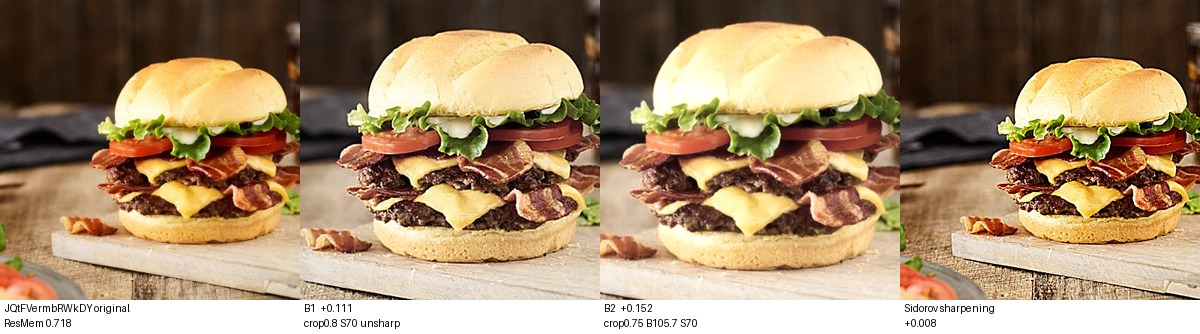

In [4]:
Show('results_test/contact_sheet.jpg')

## 5. All photographs

For each photograph: all 405 combinations of the adjustments (Method B1: the three highest ResMem kept),
Method B2: the Study 1 rule, last method is the Sidorov's nine edits. Results go to `OUT`, filed by category.

In [5]:
!"{sys.executable}" scripts/method_b.py "{PHOTO_FOLDER}" --out {OUT}

B2 targets from corpus_statistics/corpus_percentiles.json (food_photos.zip, n = 108,047): brightness P85 198.2, saturation P15 64.1, sharpness P85 1487.3
categories: burger, dessert, drink, fried, grill, noodle, other, pizza, rice, salad, soup
20 photograph(s); grid 'full' = 405 points; 414 candidates scored per photograph
loading ResMem ...
[1/20] burger/JQtFVermbRWkDYNXsJVGhA: original 0.718  B1 +0.174  B2 +0.152  (artifact-free grid points 226; 60s)
[2/20] burger/iiB5a_883CdFWv3q2j9EgQ: original 0.864  B1 +0.088  B2 +0.028  (artifact-free grid points 246; 74s)
[3/20] dessert/FzdbrnTID0spvbDQUarO9w: original 0.747  B1 +0.122  B2 +0.077  (artifact-free grid points 253; 66s)
[4/20] dessert/j4a5-Hlj3H6JiIaRlXc3yQ: original 0.805  B1 +0.087  B2 +0.075  (artifact-free grid points 221; 68s)
[5/20] drink/KBuEAp0bzcETW6RhI0fcNg: original 0.925  B1 +0.035  B2 -0.014  (artifact-free grid points 226; 81s)
[6/20] fried/1P4J68Ao1BgqrIaID-B_eg: original 0.838  B1 +0.115  B2 +0.030  (artifact-free 

c:\Users\59784\anaconda3\envs\psypher\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\59784\anaconda3\envs\psypher\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


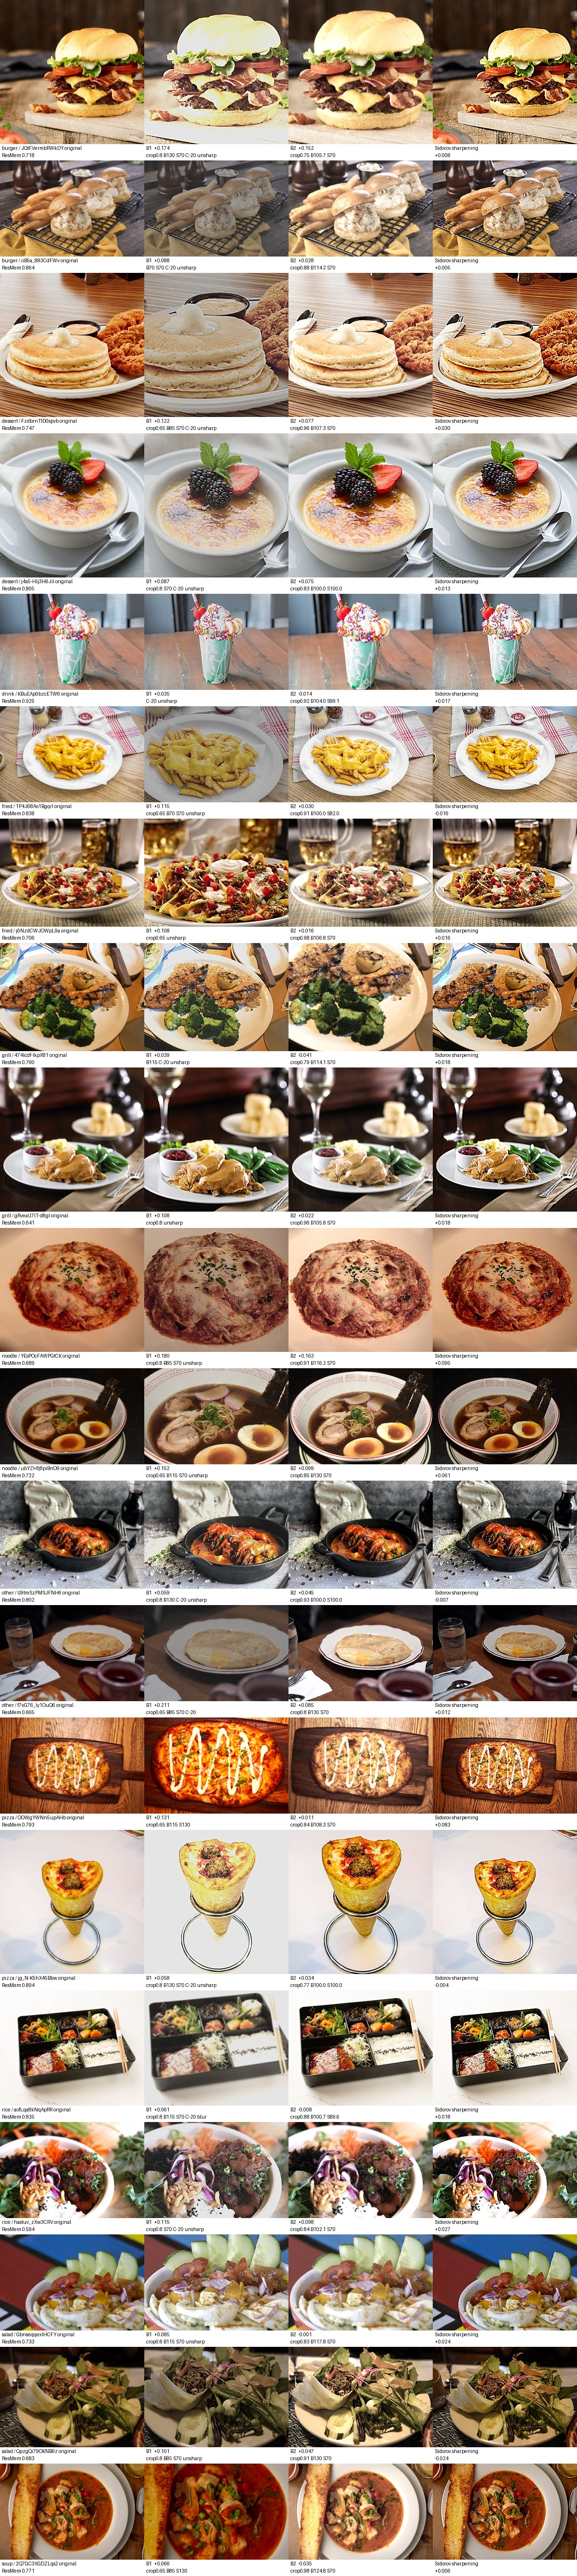

In [6]:
Show(f'{OUT}/contact_sheet.jpg')

## 6. Second model: ViTMem

ResMem picked the B1 images, so the Resmem score for the images would be flattered by the picking. ViTMem did not select pictures, so its
score is an independent check. 

In [7]:
print('images to score:', len(os.listdir(f'{OUT}/for_scoring')))

images to score: 280


In [8]:
!"{sys.executable}" scripts/score_vitmem.py {OUT}

  50/280
  100/280
  150/280
  200/280
  250/280
  280/280
wrote results_method_b\vitmem_scores.csv (280 images)


In [9]:
!"{sys.executable}" scripts/merge_scores.py {OUT} {OUT}/vitmem_scores.csv --name vitmem

merged 280 of 280 candidates into results_method_b\candidates.csv

mean change from the original   (B1 and Method A were chosen by ResMem; so ViTMem is a comparison check)
  B1 search, best per photo  n=20  ResMem +0.105   ViTMem +0.006   ViTMem>0 in 55%
  B2 Study 1 rule            n=20  ResMem +0.044   ViTMem +0.007   ViTMem>0 in 55%

paired, same photographs, ViTMem
  B2 - B1   mean +0.0012   B2 better in 10 of 20

Sidorov's tools
  bg_blur_darkening          n=20  ResMem -0.023   ViTMem -0.016   ViTMem>0 in 30%
  bg_blurring                n=20  ResMem -0.013   ViTMem -0.005   ViTMem>0 in 25%
  clarity_approx             n=20  ResMem +0.007   ViTMem -0.003   ViTMem>0 in 25%
  contrast                   n=20  ResMem -0.011   ViTMem -0.019   ViTMem>0 in 15%
  grayscaling                n=20  ResMem +0.003   ViTMem -0.055   ViTMem>0 in 5%
  sharpening                 n=20  ResMem +0.020   ViTMem -0.003   ViTMem>0 in 30%
  temperature_5000k          n=20  ResMem -0.023   ViTMem -0.006 

In [10]:
import pandas as pd, numpy as np
from scipy import stats

df = pd.read_csv(f'{OUT}/candidates.csv')
rank1 = df['rank'].fillna(0).astype(float).astype(int) == 1 if 'rank' in df else False
groups = {'B1': df[(df.method == 'B1') & rank1], 'B2': df[df.method == 'B2']}
for tool in sorted(df.loc[df.method == 'sidorov', 'candidate'].unique()):
    groups[tool.replace('sidorov_', 'Sidorov ')] = df[df.candidate == tool]

def test(d):
    d = np.asarray(d, float); d = d[~np.isnan(d)]
    m, se = d.mean(), d.std(ddof=1) / np.sqrt(len(d))
    lo, hi = stats.t.interval(0.95, len(d) - 1, loc=m, scale=se)
    return dict(n=len(d), mean=m, ci_low=lo, ci_high=hi, pct_up=(d > 0).mean(),
                p_t=stats.ttest_1samp(d, 0).pvalue, p_wilcoxon=stats.wilcoxon(d).pvalue)

def holm(p):
    p = np.asarray(p); order = np.argsort(p); adj = np.empty_like(p)
    adj[order] = np.minimum(1, np.maximum.accumulate(p[order] * (len(p) - np.arange(len(p)))))
    return adj

for score in ('d_vitmem', 'd_resmem'):
    res = pd.DataFrame({g: test(x[score]) for g, x in groups.items()}).T
    sid = res.index.str.startswith('Sidorov')
    res['p_t_holm'] = np.nan
    res.loc[sid, 'p_t_holm'] = holm(res.loc[sid, 'p_t'].astype(float))
    print(f'\n=== {score}: change from the original (edited - original), test against 0 ===')
    print('    (Holm correction across the 9 Sidorov tools; B1 on ResMem is inflated by the choosing)')
    print(res.astype(float).round(4).to_string())

# B2 vs B1, same photographs
b1 = groups['B1'].set_index('photo'); b2 = groups['B2'].set_index('photo')
common = b1.index.intersection(b2.index)
for score in ('d_vitmem', 'd_resmem'):
    r = test(b2.loc[common, score] - b1.loc[common, score])
    print(f"\nB2 - B1 ({score}): mean {r['mean']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}], "
          f"p (t) = {r['p_t']:.3g}, p (Wilcoxon) = {r['p_wilcoxon']:.3g}, n = {r['n']}")


=== d_vitmem: change from the original (edited - original), test against 0 ===
    (Holm correction across the 9 Sidorov tools; B1 on ResMem is inflated by the choosing)
                              n    mean  ci_low  ci_high  pct_up     p_t  p_wilcoxon  p_t_holm
B1                         20.0  0.0062 -0.0037   0.0160    0.55  0.2063      0.2943       NaN
B2                         20.0  0.0074 -0.0024   0.0172    0.55  0.1297      0.1262       NaN
Sidorov bg_blur_darkening  20.0 -0.0164 -0.0270  -0.0059    0.30  0.0042      0.0105    0.0249
Sidorov bg_blurring        20.0 -0.0047 -0.0130   0.0036    0.25  0.2527      0.1429    0.5055
Sidorov clarity_approx     20.0 -0.0030 -0.0048  -0.0013    0.25  0.0019      0.0032    0.0132
Sidorov contrast           20.0 -0.0194 -0.0300  -0.0088    0.15  0.0011      0.0010    0.0090
Sidorov grayscaling        20.0 -0.0554 -0.0736  -0.0371    0.05  0.0000      0.0000    0.0000
Sidorov sharpening         20.0 -0.0029 -0.0072   0.0013    0.30  0.1